# RQ3 — Strongest and Most Consistent SATD Indicators

## Research Question

**Which planning and in-sprint signals provide the strongest and most consistent indicators of SATD risk across projects?**

## Key Finding

The strongest and most consistent information comes from **planning context—especially issue age—rather than accumulated in-sprint instability**. Some estimation and workflow counts are statistically associated with SATD, but they add little held-out predictive value and are not consistent across projects.

## Dataset Overview

The analysis covers **9,507 issues across 25 projects**.

- **2,128 issues (22.38%)** are classified as SATD.
- **7,379 issues (77.62%)** are classified as non-SATD.
- In-sprint signals are measured retrospectively through T100, the end of the sprint.

## Main Findings

### 1. Issue age is the strongest individual cross-project indicator

Permuting issue age in held-out projects reduces PR-AUC by **0.0513**, the largest reduction of any feature, and the reduction is positive in **all five folds**. In the adjusted family model, a one-standard-deviation increase in issue age is associated with **14.5% higher SATD odds** (OR = 1.145, 95% CI: 1.069–1.227).

### 2. Planning is the most important signal family

The complete XGBoost model has PR-AUC **0.2938**. Removing planning lowers PR-AUC to **0.2186**, a decrease of **0.0752**. By comparison, removing communication decreases PR-AUC by **0.0074**, and removing workflow decreases it by **0.0023**. Removing scope, estimation, or ownership does not decrease PR-AUC.

### 3. Communication contributes modest predictive information

Comment count is the strongest non-planning feature by permutation importance, reducing held-out PR-AUC by **0.0078** when disrupted, with a positive contribution in all five folds. However, its adjusted odds ratio is **0.996** with Holm-adjusted *p* = 1.0, so its predictive contribution should not be interpreted as an independent statistical association or causal effect.

### 4. Instability signals are statistically detectable but inconsistent

The adjusted family model estimates small effects for estimation instability (OR = **1.038**) and workflow instability (OR = **1.064**), while ownership instability is inversely associated (OR = **0.910**). Actual Story Point changes have OR = **1.046**, but zero held-out permutation contribution. Across 19 projects with observable process signals, the median project-level Cliff's δ is **0** for every examined change-count feature. No in-sprint instability feature is simultaneously strong, predictively useful, and cross-project consistent.

### 5. Overall predictive performance remains modest

The complete XGBoost model achieves mean **PR-AUC 0.294**, **ROC-AUC 0.591**, and PR-AUC lift **1.335**. These values indicate limited discrimination even after the entire sprint has been observed.

## Overall Conclusion

**Issue age and the broader planning context are the strongest and most consistent retrospective SATD indicators.** Communication adds modest predictive information, while scope, estimation, workflow, and ownership instability signals are weak or inconsistent across projects. Because RQ3 uses complete-sprint information, it ranks retrospective indicators rather than establishing actionable early-warning signals; warning timing is evaluated in RQ4.


In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from statsmodels.genmod import families, cov_struct
    import statsmodels.formula.api as smf
    from statsmodels.stats.multitest import multipletests
    from scipy.stats import mannwhitneyu
    from sklearn.compose import ColumnTransformer
    from sklearn.inspection import permutation_importance
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import (
        average_precision_score,
        brier_score_loss,
        f1_score,
        precision_score,
        recall_score,
        roc_auc_score,
    )
    from sklearn.model_selection import StratifiedGroupKFold
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError(
        "Install dependencies with: %pip install pandas numpy scipy "
        "statsmodels scikit-learn xgboost matplotlib"
    ) from exc

OUTPUT_DIR = Path("rq3_results")
OUTPUT_DIR.mkdir(exist_ok=True)

df = pd.read_csv("rq3_signal_dataset.csv")
df["is_satd"] = pd.to_numeric(df["is_satd"], errors="coerce")
df = df[df["is_satd"].isin([0, 1])].copy()
df["is_satd"] = df["is_satd"].astype(int)

print("Shape:", df.shape)
print("Projects:", df["project_id"].nunique())
print("Issues:", df["issue_id"].nunique())
print("Duplicate issue IDs:", df["issue_id"].duplicated().sum())
print("SATD distribution:\n", df["is_satd"].value_counts())
print("SATD prevalence:", df["is_satd"].mean())

Shape: (9507, 47)
Projects: 25
Issues: 9507
Duplicate issue IDs: 0
SATD distribution:
 is_satd
0    7379
1    2128
Name: count, dtype: int64
SATD prevalence: 0.2238350688966025


In [3]:
planning_categorical = ["priority_group", "issue_type_group"]
planning_numeric = [
    "project_sp_percentile", "story_point_missing_or_zero",
    "issue_age_days_at_sprint_start", "urgent_issue_ratio",
]

scope_raw = [
    "description_change_count", "summary_change_count",
    "acceptance_criteria_change_count", "issue_type_change_count",
]
estimation_raw = [
    "story_point_change_count", "actual_story_point_change_count",
    "time_estimate_change_count",
]
workflow_raw = [
    "status_transition_count", "blocked_count", "reopen_count",
    "review_return_count", "testing_return_count", "rework_entry_count",
    "backward_transition_count",
]
ownership_raw = [
    "assignee_change_count", "team_change_count", "sprint_change_count",
    "priority_change_count",
]
communication_raw = ["comment_count", "unique_commenters", "unique_change_authors"]

sprint_df = (
    df[["project_id", "sprint_id", "sprint_issue_count", "estimated_issue_count", "sprint_total_story_points"]]
    .drop_duplicates(["project_id", "sprint_id"])
    .copy()
)
sprint_df["sprint_issue_count_percentile"] = sprint_df.groupby("project_id")["sprint_issue_count"].rank(pct=True)
sprint_df["sprint_sp_load_percentile"] = sprint_df.groupby("project_id")["sprint_total_story_points"].rank(pct=True)
sprint_df["estimated_issue_ratio"] = sprint_df["estimated_issue_count"] / sprint_df["sprint_issue_count"].replace(0, np.nan)

df = df.merge(
    sprint_df[["project_id", "sprint_id", "sprint_issue_count_percentile", "sprint_sp_load_percentile", "estimated_issue_ratio"]],
    on=["project_id", "sprint_id"], how="left",
)
planning_numeric += ["sprint_issue_count_percentile", "sprint_sp_load_percentile", "estimated_issue_ratio"]

process_raw_features = scope_raw + estimation_raw + workflow_raw + ownership_raw + communication_raw
for col in process_raw_features:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)
    df[f"log_{col}"] = np.log1p(df[col].clip(lower=0))

scope_features = [f"log_{x}" for x in scope_raw]
estimation_features = [f"log_{x}" for x in estimation_raw]
workflow_features = [f"log_{x}" for x in workflow_raw]
ownership_features = [f"log_{x}" for x in ownership_raw]
communication_features = [f"log_{x}" for x in communication_raw]

# Explicit totals are used for inferential family-level comparisons only.
df["scope_instability_count"] = df[scope_raw].sum(axis=1)
df["estimation_instability_count"] = df[estimation_raw].sum(axis=1)
df["workflow_instability_count"] = df[workflow_raw].sum(axis=1)
df["ownership_instability_count"] = df[ownership_raw].sum(axis=1)
family_raw = [
    "scope_instability_count", "estimation_instability_count",
    "workflow_instability_count", "ownership_instability_count",
]
for col in family_raw:
    df[f"log_{col}"] = np.log1p(df[col].clip(lower=0))

family_summary = []
for feature in family_raw:
    for satd_value, label in [(0, "Non-SATD"), (1, "SATD")]:
        values = df.loc[df["is_satd"] == satd_value, feature]
        family_summary.append({
            "family": feature, "group": label, "n": values.notna().sum(),
            "mean": values.mean(), "median": values.median(),
            "q1": values.quantile(.25), "q3": values.quantile(.75),
        })
family_summary = pd.DataFrame(family_summary)
family_summary.to_csv(OUTPUT_DIR / "family_descriptive_summary.csv", index=False)
family_summary

,family,group,n,mean,median,q1,q3
0,scope_instability_count,Non-SATD,7379,0.017482,0.0,0.0,0.0
1,scope_instability_count,SATD,2128,0.013158,0.0,0.0,0.0
2,estimation_instability_count,Non-SATD,7379,0.022767,0.0,0.0,0.0
3,estimation_instability_count,SATD,2128,0.017387,0.0,0.0,0.0
4,workflow_instability_count,Non-SATD,7379,0.207345,0.0,0.0,0.0
5,workflow_instability_count,SATD,2128,0.134398,0.0,0.0,0.0
6,ownership_instability_count,Non-SATD,7379,0.096083,0.0,0.0,0.0
7,ownership_instability_count,SATD,2128,0.049812,0.0,0.0,0.0


In [4]:
gee_df = df.copy()
gee_numeric = [
    "project_sp_percentile", "issue_age_days_at_sprint_start", "urgent_issue_ratio",
    "sprint_issue_count_percentile", "sprint_sp_load_percentile", "estimated_issue_ratio",
    "log_scope_instability_count", "log_estimation_instability_count",
    "log_workflow_instability_count", "log_ownership_instability_count",
]
for col in gee_numeric:
    values = pd.to_numeric(gee_df[col], errors="coerce")
    values = values.fillna(values.median())
    std = values.std()
    gee_df[f"z_{col}"] = (values - values.mean()) / std if std > 0 else 0

priority_ref = "MEDIUM" if "MEDIUM" in gee_df["priority_group"].dropna().unique() else gee_df["priority_group"].mode()[0]
type_ref = "TECHNICAL_WORK" if "TECHNICAL_WORK" in gee_df["issue_type_group"].dropna().unique() else gee_df["issue_type_group"].mode()[0]

def gee_formula(signal_term):
    return f"""is_satd ~ {signal_term}
        + C(priority_group, Treatment(reference='{priority_ref}'))
        + C(issue_type_group, Treatment(reference='{type_ref}'))
        + z_project_sp_percentile + story_point_missing_or_zero
        + z_issue_age_days_at_sprint_start + z_urgent_issue_ratio
        + z_sprint_issue_count_percentile + z_sprint_sp_load_percentile
        + z_estimated_issue_ratio"""

family_formula = gee_formula(
    "z_log_scope_instability_count + z_log_estimation_instability_count "
    "+ z_log_workflow_instability_count + z_log_ownership_instability_count"
)
family_result = smf.gee(
    formula=family_formula, groups="project_id", data=gee_df,
    family=families.Binomial(), cov_struct=cov_struct.Exchangeable(),
).fit()

coef = family_result.params
ci = family_result.conf_int()
family_or = pd.DataFrame({
    "term": coef.index, "coefficient": coef.values,
    "adjusted_OR": np.exp(coef.values), "ci_lower": np.exp(ci[0].values),
    "ci_upper": np.exp(ci[1].values), "p_value": family_result.pvalues.values,
})
family_or = family_or[family_or["term"] != "Intercept"].copy()
family_or.to_csv(OUTPUT_DIR / "family_adjusted_odds_ratios.csv", index=False)
print(family_result.summary())
print(family_or[family_or["term"].str.contains("instability")])

individual_results = []
for raw_signal in scope_raw + estimation_raw + workflow_raw + ownership_raw + communication_raw:
    signal = f"log_{raw_signal}"
    values = pd.to_numeric(gee_df[signal], errors="coerce").fillna(0)
    std = values.std()
    if std == 0:
        continue
    temp = gee_df.copy()
    temp[f"z_{signal}"] = (values - values.mean()) / std
    try:
        result = smf.gee(
            formula=gee_formula(f"z_{signal}"), groups="project_id", data=temp,
            family=families.Binomial(), cov_struct=cov_struct.Exchangeable(),
        ).fit()
        beta = result.params[f"z_{signal}"]
        signal_ci = result.conf_int().loc[f"z_{signal}"]
        individual_results.append({
            "signal": raw_signal, "adjusted_OR": np.exp(beta),
            "ci_lower": np.exp(signal_ci.iloc[0]), "ci_upper": np.exp(signal_ci.iloc[1]),
            "p_value": result.pvalues[f"z_{signal}"],
        })
    except Exception as exc:
        print(f"Failed: {raw_signal}: {exc}")

individual_results = pd.DataFrame(individual_results)
individual_results["p_holm"] = multipletests(individual_results["p_value"], method="holm")[1]
individual_results["effect_from_OR_pct"] = (individual_results["adjusted_OR"] - 1) * 100
individual_results = individual_results.sort_values("adjusted_OR", ascending=False)
individual_results.to_csv(OUTPUT_DIR / "individual_signal_adjusted_associations.csv", index=False)
individual_results.head(20)

                               GEE Regression Results                              
Dep. Variable:                     is_satd   No. Observations:                 9507
Model:                                 GEE   No. clusters:                       25
Method:                        Generalized   Min. cluster size:                   5
                      Estimating Equations   Max. cluster size:                1612
Family:                           Binomial   Mean cluster size:               380.3
Dependence structure:         Exchangeable   Num. iterations:                    10
Date:                     Tue, 08 Sep 2026   Scale:                           1.000
Covariance type:                    robust   Time:                         00:41:23
                                                                                          coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------

,signal,adjusted_OR,ci_lower,ci_upper,p_value,p_holm,effect_from_OR_pct
5,actual_story_point_change_count,1.046089,1.040581,1.051627,8.314202e-63,1.496556e-61,4.608931
7,status_transition_count,1.037148,0.947231,1.135600,4.305240e-01,1.000000e+00,3.714755
3,issue_type_change_count,1.025518,1.004068,1.047426,1.947041e-02,2.920561e-01,2.551812
11,backward_transition_count,1.021797,1.000997,1.043029,3.989041e-02,5.584657e-01,2.179672
0,description_change_count,1.020935,0.987957,1.055013,2.161819e-01,1.000000e+00,2.093488
1,summary_change_count,1.007736,0.954791,1.063617,7.795837e-01,1.000000e+00,0.773595
4,story_point_change_count,1.007320,1.005561,1.009082,2.865717e-16,4.871719e-15,0.732026
15,comment_count,0.996046,0.932705,1.063688,9.059209e-01,1.000000e+00,-0.395412
16,unique_commenters,0.991181,0.938113,1.047250,7.523651e-01,1.000000e+00,-0.881918
13,sprint_change_count,0.970552,0.924668,1.018713,2.264057e-01,1.000000e+00,-2.944833


In [5]:
family_features = {
    "Planning": planning_categorical + planning_numeric,
    "Scope": scope_features,
    "Estimation": estimation_features,
    "Workflow": workflow_features,
    "Ownership": ownership_features,
    "Communication": communication_features,
}
planning_features = family_features["Planning"]

incremental_sets = {
    "M1_Planning": planning_features,
    "M2_Planning_Scope": planning_features + scope_features,
    "M3_Add_Estimation": planning_features + scope_features + estimation_features,
    "M4_Add_Workflow": planning_features + scope_features + estimation_features + workflow_features,
    "M5_Add_Ownership": planning_features + scope_features + estimation_features + workflow_features + ownership_features,
    "M6_Add_Communication": planning_features + scope_features + estimation_features + workflow_features + ownership_features + communication_features,
}
full_features = incremental_sets["M6_Add_Communication"]

def build_pipeline(features, model_type="lr"):
    categorical = [feature for feature in features if feature in planning_categorical]
    numeric = [feature for feature in features if feature not in categorical]
    preprocessor = ColumnTransformer([
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical),
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric),
    ])
    if model_type == "lr":
        model = LogisticRegression(max_iter=5000, random_state=42)
    elif model_type == "xgb":
        model = XGBClassifier(
            n_estimators=500, max_depth=4, learning_rate=0.03,
            subsample=0.8, colsample_bytree=0.8,
            objective="binary:logistic", eval_metric="logloss",
            random_state=42, n_jobs=-1,
        )
    else:
        raise ValueError("model_type must be 'lr' or 'xgb'")
    return Pipeline([("preprocessor", preprocessor), ("model", model)])

y = df["is_satd"].copy()
groups = df["project_id"].copy()
n_splits = min(5, groups.nunique())
cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=42)
splits = list(cv.split(np.zeros(len(df)), y, groups))


def evaluate_feature_set(data, features, model_type, fold_splits, model_name):
    X = data[features].copy()
    target = data["is_satd"]
    rows = []
    for fold, (train_idx, test_idx) in enumerate(fold_splits, start=1):
        pipeline = build_pipeline(features, model_type)
        pipeline.fit(X.iloc[train_idx], target.iloc[train_idx])
        probability = pipeline.predict_proba(X.iloc[test_idx])[:, 1]
        prediction = (probability >= 0.5).astype(int)
        y_test = target.iloc[test_idx]
        prevalence = y_test.mean()
        rows.append({
            "model_name": model_name, "model_type": model_type, "fold": fold,
            "test_projects": groups.iloc[test_idx].nunique(), "test_issues": len(test_idx),
            "prevalence": prevalence,
            "pr_auc": average_precision_score(y_test, probability),
            "pr_auc_lift": average_precision_score(y_test, probability) / prevalence if prevalence else np.nan,
            "roc_auc": roc_auc_score(y_test, probability) if y_test.nunique() == 2 else np.nan,
            "precision": precision_score(y_test, prediction, zero_division=0),
            "recall": recall_score(y_test, prediction, zero_division=0),
            "f1": f1_score(y_test, prediction, zero_division=0),
            "brier": brier_score_loss(y_test, probability),
        })
    return pd.DataFrame(rows)

incremental_results = []
for model_type in ["lr", "xgb"]:
    for name, features in incremental_sets.items():
        print(f"Running {model_type.upper()}: {name}")
        incremental_results.append(evaluate_feature_set(df, features, model_type, splits, name))
incremental_results = pd.concat(incremental_results, ignore_index=True)
incremental_results.to_csv(OUTPUT_DIR / "incremental_model_fold_results.csv", index=False)

incremental_summary = incremental_results.groupby(["model_type", "model_name"]).agg(
    pr_auc_mean=("pr_auc", "mean"), pr_auc_std=("pr_auc", "std"),
    roc_auc_mean=("roc_auc", "mean"), f1_mean=("f1", "mean"),
    precision_mean=("precision", "mean"), recall_mean=("recall", "mean"),
    brier_mean=("brier", "mean"), pr_auc_lift_mean=("pr_auc_lift", "mean"),
).reset_index()
model_order = list(incremental_sets)
for model_type in ["lr", "xgb"]:
    mask = incremental_summary["model_type"].eq(model_type)
    ordered = incremental_summary.loc[mask].copy()
    ordered["model_name"] = pd.Categorical(ordered["model_name"], categories=model_order, ordered=True)
    ordered = ordered.sort_values("model_name")
    ordered["incremental_pr_auc_gain"] = ordered["pr_auc_mean"].diff()
    print(f"\n{model_type.upper()} incremental gains")
    print(ordered[["model_name", "pr_auc_mean", "incremental_pr_auc_gain"]])
incremental_summary.to_csv(OUTPUT_DIR / "incremental_model_summary.csv", index=False)

Running LR: M1_Planning
Running LR: M2_Planning_Scope
Running LR: M3_Add_Estimation
Running LR: M4_Add_Workflow
Running LR: M5_Add_Ownership
Running LR: M6_Add_Communication
Running XGB: M1_Planning
Running XGB: M2_Planning_Scope
Running XGB: M3_Add_Estimation
Running XGB: M4_Add_Workflow
Running XGB: M5_Add_Ownership
Running XGB: M6_Add_Communication

LR incremental gains
             model_name  pr_auc_mean  incremental_pr_auc_gain
0           M1_Planning     0.245509                      NaN
1     M2_Planning_Scope     0.244011                -0.001497
2     M3_Add_Estimation     0.244016                 0.000005
3       M4_Add_Workflow     0.242856                -0.001160
4      M5_Add_Ownership     0.242940                 0.000084
5  M6_Add_Communication     0.241449                -0.001491

XGB incremental gains
              model_name  pr_auc_mean  incremental_pr_auc_gain
6            M1_Planning     0.291351                      NaN
7      M2_Planning_Scope     0.288330    

In [6]:
full_results = evaluate_feature_set(df, full_features, "xgb", splits, "Full")
full_pr_auc = full_results["pr_auc"].mean()

ablation_families = family_features.copy()
ablation_results = []
for family, remove_features in ablation_families.items():
    reduced_features = [feature for feature in full_features if feature not in remove_features]
    result = evaluate_feature_set(df, reduced_features, "xgb", splits, f"Without_{family}")
    reduced_pr_auc = result["pr_auc"].mean()
    ablation_results.append({
        "removed_family": family,
        "full_pr_auc": full_pr_auc,
        "without_family_pr_auc": reduced_pr_auc,
        "pr_auc_drop": full_pr_auc - reduced_pr_auc,
    })
ablation_results = pd.DataFrame(ablation_results).sort_values("pr_auc_drop", ascending=False)
ablation_results.to_csv(OUTPUT_DIR / "family_ablation_results.csv", index=False)
print("Full model PR-AUC:", full_pr_auc)
ablation_results

Full model PR-AUC: 0.29378189670597676


,removed_family,full_pr_auc,without_family_pr_auc,pr_auc_drop
0,Planning,0.293782,0.218601,0.075181
5,Communication,0.293782,0.286413,0.007369
3,Workflow,0.293782,0.291518,0.002264
4,Ownership,0.293782,0.294078,-0.000296
2,Estimation,0.293782,0.294500,-0.000718
1,Scope,0.293782,0.296275,-0.002493


In [7]:
permutation_rows = []
X_full = df[full_features].copy()
for fold, (train_idx, test_idx) in enumerate(splits, start=1):
    print(f"Permutation importance fold {fold}")
    model = build_pipeline(full_features, "xgb")
    model.fit(X_full.iloc[train_idx], y.iloc[train_idx])
    importance = permutation_importance(
        model, X_full.iloc[test_idx], y.iloc[test_idx],
        scoring="average_precision", n_repeats=10, random_state=42 + fold, n_jobs=-1,
    )
    permutation_rows.extend({
        "fold": fold, "feature": feature,
        "importance_mean": mean_imp, "importance_std": std_imp,
    } for feature, mean_imp, std_imp in zip(full_features, importance.importances_mean, importance.importances_std))

permutation_df = pd.DataFrame(permutation_rows)
permutation_summary = permutation_df.groupby("feature").agg(
    mean_pr_auc_drop=("importance_mean", "mean"),
    std_pr_auc_drop=("importance_mean", "std"),
    positive_folds=("importance_mean", lambda values: (values > 0).sum()),
    total_folds=("importance_mean", "count"),
).reset_index()
permutation_summary["positive_fold_percentage"] = 100 * permutation_summary["positive_folds"] / permutation_summary["total_folds"]
permutation_summary = permutation_summary.sort_values("mean_pr_auc_drop", ascending=False)
permutation_summary.to_csv(OUTPUT_DIR / "cross_project_permutation_importance.csv", index=False)
permutation_summary.head(20)

Permutation importance fold 1
Permutation importance fold 2
Permutation importance fold 3
Permutation importance fold 4
Permutation importance fold 5


,feature,mean_pr_auc_drop,std_pr_auc_drop,positive_folds,total_folds,positive_fold_percentage
1,issue_age_days_at_sprint_start,0.051277,0.033480,5,5,100.0
27,sprint_sp_load_percentile,0.010772,0.011039,4,5,80.0
8,log_comment_count,0.007757,0.006726,5,5,100.0
24,priority_group,0.007175,0.008928,4,5,80.0
25,project_sp_percentile,0.006507,0.012028,3,5,60.0
0,estimated_issue_ratio,0.005891,0.010145,3,5,60.0
26,sprint_issue_count_percentile,0.005240,0.006431,4,5,80.0
2,issue_type_group,0.005076,0.004758,4,5,80.0
29,urgent_issue_ratio,0.003492,0.007599,3,5,60.0
23,log_unique_commenters,0.001215,0.002038,4,5,80.0


In [8]:
def project_cliffs_delta(data, feature, min_group_size=20):
    rows = []
    for project_id, project in data.groupby("project_id"):
        satd = project.loc[project["is_satd"] == 1, feature].dropna().astype(float).values
        non_satd = project.loc[project["is_satd"] == 0, feature].dropna().astype(float).values
        if len(satd) < min_group_size or len(non_satd) < min_group_size:
            continue
        u_stat, _ = mannwhitneyu(satd, non_satd, alternative="two-sided")
        delta = 2 * u_stat / (len(satd) * len(non_satd)) - 1
        rows.append({
            "project_id": project_id, "feature": feature,
            "cliffs_delta": delta, "satd_n": len(satd), "non_satd_n": len(non_satd),
        })
    return pd.DataFrame(rows)

consistency_rows = []
for feature in scope_raw + estimation_raw + workflow_raw + ownership_raw:
    effects = project_cliffs_delta(df, feature)
    if not effects.empty:
        consistency_rows.append(effects)
project_effects = pd.concat(consistency_rows, ignore_index=True)
project_consistency = project_effects.groupby("feature").agg(
    projects=("project_id", "nunique"), median_delta=("cliffs_delta", "median"),
    mean_delta=("cliffs_delta", "mean"),
    positive_projects_pct=("cliffs_delta", lambda values: 100 * (values > 0).mean()),
    negative_projects_pct=("cliffs_delta", lambda values: 100 * (values < 0).mean()),
    meaningful_positive_pct=("cliffs_delta", lambda values: 100 * (values >= 0.147).mean()),
).reset_index().sort_values("positive_projects_pct", ascending=False)
project_effects.to_csv(OUTPUT_DIR / "project_level_signal_effects.csv", index=False)
project_consistency.to_csv(OUTPUT_DIR / "project_level_signal_consistency.csv", index=False)
project_consistency

,feature,projects,median_delta,mean_delta,positive_projects_pct,negative_projects_pct,meaningful_positive_pct
1,actual_story_point_change_count,19,0.0,0.002763,5.263158,0.000000,0.0
3,backward_transition_count,19,0.0,0.001131,5.263158,0.000000,0.0
12,status_transition_count,19,0.0,0.003340,5.263158,5.263158,0.0
5,description_change_count,19,0.0,0.001354,5.263158,0.000000,0.0
6,issue_type_change_count,19,0.0,0.001010,5.263158,0.000000,0.0
13,story_point_change_count,19,0.0,0.000628,5.263158,0.000000,0.0
14,summary_change_count,19,0.0,0.001193,5.263158,0.000000,0.0
0,acceptance_criteria_change_count,19,0.0,-0.000124,0.000000,5.263158,0.0
4,blocked_count,19,0.0,0.000000,0.000000,0.000000,0.0
2,assignee_change_count,19,0.0,-0.002707,0.000000,10.526316,0.0


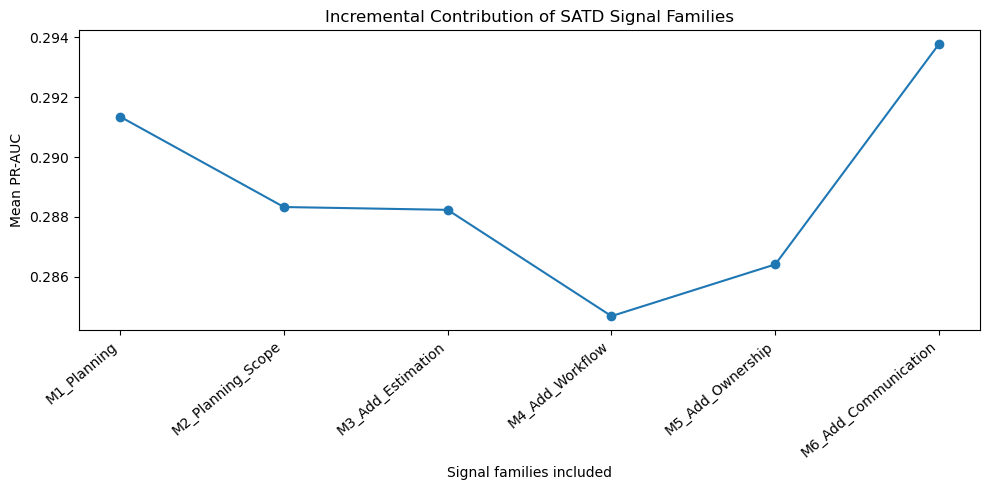

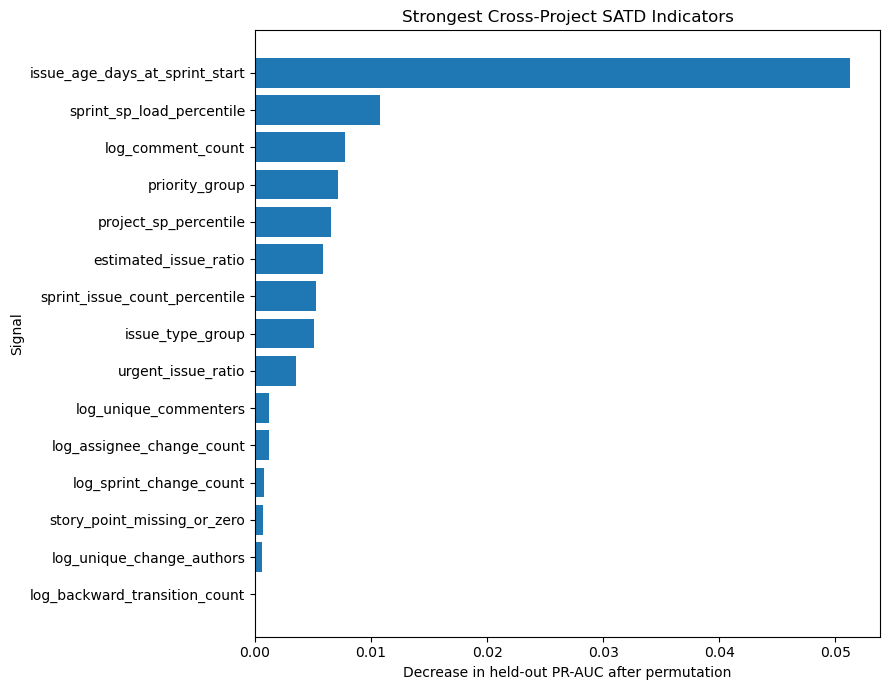

RQ3 outputs written to: E:\SATD-Agile\rq3_results
Top merged signal ranking:


,signal,adjusted_OR,ci_lower,ci_upper,p_holm,mean_pr_auc_drop,positive_fold_percentage,median_delta,positive_projects_pct
7,comment_count,0.996046,0.932705,1.063688,1.000000e+00,0.007757,100.0,NaN,NaN
8,unique_commenters,0.991181,0.938113,1.047250,1.000000e+00,0.001215,80.0,NaN,NaN
12,assignee_change_count,0.941147,0.877637,1.009254,1.000000e+00,0.001164,20.0,0.0,0.000000
9,sprint_change_count,0.970552,0.924668,1.018713,1.000000e+00,0.000789,40.0,0.0,0.000000
10,unique_change_authors,0.968076,0.884537,1.059506,1.000000e+00,0.000623,40.0,NaN,NaN
3,backward_transition_count,1.021797,1.000997,1.043029,5.584657e-01,0.000070,40.0,0.0,5.263158
0,actual_story_point_change_count,1.046089,1.040581,1.051627,1.496556e-61,0.000000,0.0,0.0,5.263158
6,story_point_change_count,1.007320,1.005561,1.009082,4.871719e-15,0.000000,0.0,0.0,5.263158
11,priority_change_count,0.964973,0.939371,0.991274,1.496772e-01,0.000000,0.0,0.0,0.000000
13,acceptance_criteria_change_count,NaN,NaN,NaN,NaN,0.000000,0.0,0.0,0.000000


In [9]:
permutation_process = permutation_summary.copy()
permutation_process["signal"] = permutation_process["feature"].str.replace("^log_", "", regex=True)

rq3_ranking = individual_results.merge(
    permutation_process[["signal", "mean_pr_auc_drop", "positive_fold_percentage"]],
    on="signal", how="left",
).merge(
    project_consistency[["feature", "projects", "median_delta", "positive_projects_pct"]],
    left_on="signal", right_on="feature", how="left",
)
rq3_ranking["importance_rank"] = rq3_ranking["mean_pr_auc_drop"].rank(ascending=False, method="min")
rq3_ranking["association_rank"] = rq3_ranking["adjusted_OR"].rank(ascending=False, method="min")
rq3_ranking = rq3_ranking.sort_values(["importance_rank", "association_rank"], na_position="last")
rq3_ranking.to_csv(OUTPUT_DIR / "rq3_final_signal_ranking.csv", index=False)

plot_df = incremental_summary[incremental_summary["model_type"] == "xgb"].copy()
plot_df["model_name"] = pd.Categorical(plot_df["model_name"], categories=model_order, ordered=True)
plot_df = plot_df.sort_values("model_name")
plt.figure(figsize=(10, 5))
plt.plot(plot_df["model_name"].astype(str), plot_df["pr_auc_mean"], marker="o")
plt.xticks(rotation=40, ha="right")
plt.ylabel("Mean PR-AUC")
plt.xlabel("Signal families included")
plt.title("Incremental Contribution of SATD Signal Families")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "incremental_pr_auc.png", dpi=300)
plt.show()

top_features = permutation_summary.head(15).sort_values("mean_pr_auc_drop")
plt.figure(figsize=(9, 7))
plt.barh(top_features["feature"], top_features["mean_pr_auc_drop"])
plt.xlabel("Decrease in held-out PR-AUC after permutation")
plt.ylabel("Signal")
plt.title("Strongest Cross-Project SATD Indicators")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_signal_importance.png", dpi=300)
plt.show()

print("RQ3 outputs written to:", OUTPUT_DIR.resolve())
print("Top merged signal ranking:")
rq3_ranking[[
    "signal", "adjusted_OR", "ci_lower", "ci_upper", "p_holm",
    "mean_pr_auc_drop", "positive_fold_percentage", "median_delta", "positive_projects_pct",
]].head(15)